In [1]:
import sys
sys.path.append("..")

from src.data import load_events, add_xy, filter_events
from src.features import *
from src.viz import *
import matplotlib.pyplot as plt


pitch = VerticalPitch(half=True, pitch_type="statsbomb", line_color="#444")
events = add_xy(load_events(18245))
match_summary(events)

,shots,on_target,goals,xg,shot_accuracy_%,shot_share_%,passes,completed,pass_accuracy_%,pass_share_%
team,,,,,,,,,,
Liverpool,14,3,1,1.43,21.4,50.0,360,266,73.9,34.8
Real Madrid,14,6,3,1.68,42.9,50.0,673,596,88.6,65.2


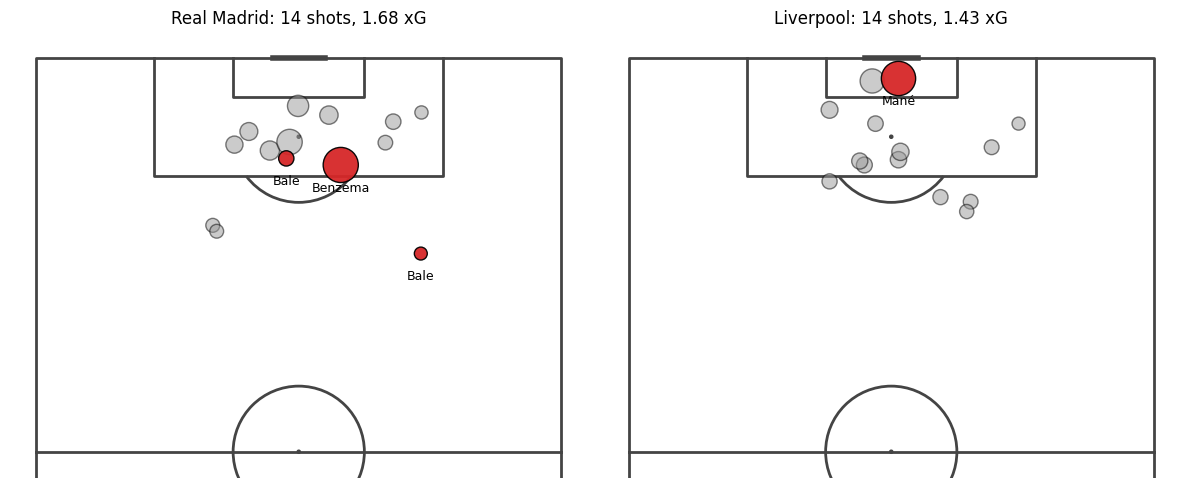

In [4]:
shots = filter_events(regular_play(events), "Shot")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, team in zip(axes, get_teams(events)):
    plot_shot_map(shots, team, ax=ax)
plt.tight_layout()
fig.savefig("../outputs/figures/shot_maps.png", dpi=150, bbox_inches="tight")

In [9]:
from src.features import passing_network
from src.viz import plot_pass_network

nodes, edges = passing_network(events, "Liverpool", min_passes=2)
edges.sort_values("passes", ascending=False)     # who touched the ball most?

,player_a,player_b,passes,x_a,y_a,x_b,y_b
0,Andrew Robertson,Virgil van Dijk,13,63.793939,6.909091,45.900000,22.475000
1,Georginio Wijnaldum,Trent Alexander-Arnold,13,67.753333,47.436667,56.871429,72.647619
2,Dejan Lovren,Loris Karius,12,39.568000,58.256000,14.876190,40.014286
3,Andrew Robertson,Jordan Brian Henderson,10,63.793939,6.909091,55.817949,38.125641
4,Andrew Robertson,James Philip Milner,10,63.793939,6.909091,70.858333,34.045833
5,Dejan Lovren,Jordan Brian Henderson,9,39.568000,58.256000,55.817949,38.125641
6,Dejan Lovren,Virgil van Dijk,9,39.568000,58.256000,45.900000,22.475000
7,Dejan Lovren,Trent Alexander-Arnold,8,39.568000,58.256000,56.871429,72.647619
8,Andrew Robertson,Georginio Wijnaldum,8,63.793939,6.909091,67.753333,47.436667
9,Jordan Brian Henderson,Trent Alexander-Arnold,8,55.817949,38.125641,56.871429,72.647619


In [8]:
nodes, edges = passing_network(events, "Real Madrid", min_passes=2)
edges.sort_values("passes", ascending=False)

,player_a,player_b,passes,x_a,y_a,x_b,y_b
0,Raphaël Varane,Sergio Ramos García,33,42.833333,56.257407,45.134615,27.002564
1,Sergio Ramos García,Toni Kroos,31,45.134615,27.002564,60.036905,28.296429
2,Cristiano Ronaldo dos Santos Aveiro,Marcelo Vieira da Silva Júnior,29,78.506061,18.130303,68.600000,9.594366
3,Marcelo Vieira da Silva Júnior,Toni Kroos,28,68.600000,9.594366,60.036905,28.296429
4,Marcelo Vieira da Silva Júnior,Sergio Ramos García,26,68.600000,9.594366,45.134615,27.002564
5,José Ignacio Fernández Iglesias,Luka Modrić,26,66.734783,71.741304,63.550746,57.282090
6,Luka Modrić,Toni Kroos,24,63.550746,57.282090,60.036905,28.296429
7,Karim Benzema,Marcelo Vieira da Silva Júnior,20,77.894444,25.319444,68.600000,9.594366
8,Francisco Román Alarcón Suárez,Toni Kroos,19,74.119149,40.572340,60.036905,28.296429
9,Daniel Carvajal Ramos,Luka Modrić,18,64.341667,73.875000,63.550746,57.282090


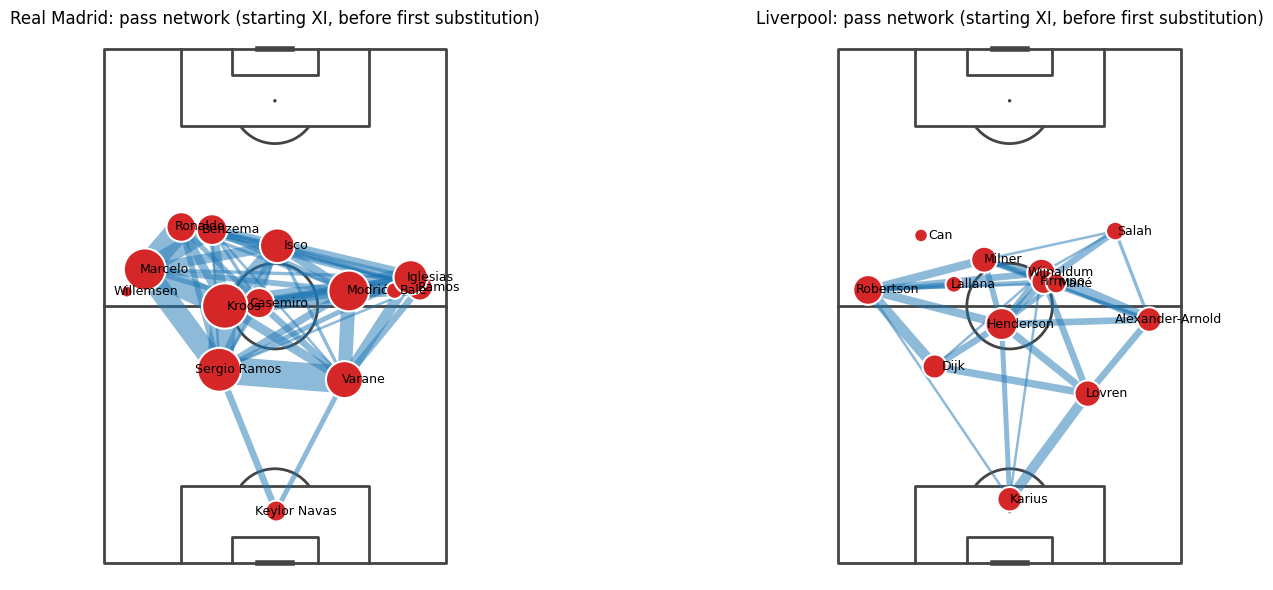

In [7]:
# StatsBomb uses full legal names, so the default label can be wrong
pitch = VerticalPitch(half=False, pitch_type="statsbomb", line_color="#444")
labels = {
    "Roberto Firmino Barbosa de Oliveira": "Firmino",
    "Francisco Román Alarcón Suárez": "Isco",
    "Cristiano Ronaldo dos Santos Aveiro": "Ronaldo",
    "Carlos Henrique Casimiro": "Casemiro",
    "Sergio Ramos García": "Sergio Ramos",
    "Marcelo Vieira da Silva Júnior": "Marcelo",
    "Keylor Navas Gamboa": "Keylor Navas",
}

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, team in zip(axes, get_teams(events)):
    nodes, edges = passing_network(events, team)
    plot_pass_network(pitch,nodes, edges, team, labels=labels, ax=ax)
plt.tight_layout()
fig.savefig("../outputs/figures/pass_networks.png", dpi=150, bbox_inches="tight")

In [3]:
pressing_summary(events)

,pressures,opp_half_%,final_third_%
team,,,
Liverpool,134,46.3,16.4
Real Madrid,92,39.1,15.2


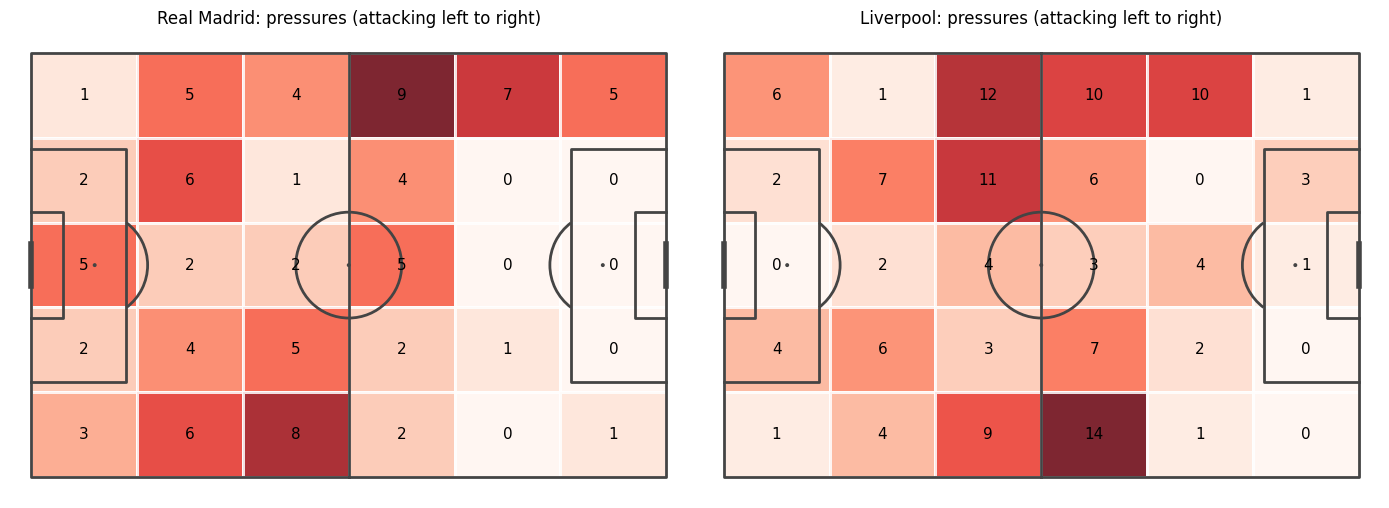

In [2]:
pitch = Pitch(half=False, pitch_type="statsbomb", line_color="#444", line_zorder=3)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, team in zip(axes, get_teams(events)):
    pressures = event_locations(events, ["Pressure"], team)
    plot_heatmap(pressures, pitch, f"{team}: pressures (attacking left to right)", ax=ax)
plt.tight_layout()
fig.savefig("../outputs/figures/pressing_zones.png", dpi=150, bbox_inches="tight")